<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"></ul></div>

Code to produce Figure 2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv

plt.rcParams.update({
    "font.family": 'Arial', 
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.titlesize": 14
})

In [2]:
twopi = 2 * np.pi

######### Atomic Units #########
################################
## Charge: e > 0              ##
## Ang. momentum: hbar        ##
## Mass: m_e                  ##
## Permittivity: 4 pi eps_0   ## 
## Temperature: 1 K           ##
################################
################################

# Values in SI
e_mass = 9.1093837e-31                                            # electron mass
e_charge = 1.6021766e-19                                          # positron charge
hbar = 1.0545718e-34                                              # reduced Planck's constant
eps_0 = 8.8541878e-12                                             # Free space permittivity
kb = 1.380649e-23                                                 # Boltzmann constant
Eh = e_mass * e_charge**4 * (2 * twopi * eps_0)**-2 * hbar**-2    # Hartree (4.360e-18)

# useful conversion
kb_atomic = kb / Eh                                               # (3.167e-06)
ev_atomic = e_charge / Eh                                         # (0.0367)
THz_atomic = 10**12 * (hbar * twopi) / Eh                         # (1.520e-4)

Fermi function (equilibrium)

\begin{align}
    f(E) = \frac{1}{1 + e^{\beta (E-\mu)}}
\end{align}

In [3]:
# Take chemical potential to be zero
def fermi(E, beta):
    expo = np.minimum(99, beta * E) # min to prevent overflow
    return 1/(np.exp(expo) + 1)

Staircase Fermi function (Floquet drive)

\begin{align}
    \rho_F = \sum_{\xi} f(\epsilon_0 + \xi \hbar\Omega) |P_{\xi}|^2
\end{align}

$1 \times 1$ Hamiltonian with sinusoidal drive
\begin{align}
    H(t) = \epsilon_0 + 2 \epsilon_1 \cos \Omega t 
\end{align}

Fourier series of micromotion operator 
\begin{align}
    P_{\xi} = J_{\xi}\left(\frac{2 \epsilon_1}{\hbar\Omega}\right) 
\end{align}
where $J_\xi$ is the $\xi$-th order Bessel function. 
<br><br>
Note that
\begin{align}
    J_{-\xi}(z) = (-1)^{\xi} J_{\xi}(z) 
\end{align}

In [4]:
NF = 120
Omega = 50 * THz_atomic

def weights_array(Omega, eps1):
    strength = 2 * eps1 / Omega
    
    return jv(np.arange(NF+1), strength)**2

In [5]:
def fermi_array(eps0, beta, Omega):
    arr = np.zeros(2 * NF + 1)
    
    for xi in range(-NF, NF+1):
        arr[xi+NF] = fermi(eps0 + xi * Omega, beta)
        
    return arr

In [6]:
def fermi_floquet(weights_arr, fermi_arr):
    
    res = weights_arr[0] * fermi_arr[NF]
    
    for xi in range(1, NF+1):
        res += weights_arr[xi] * (fermi_arr[NF+xi] + fermi_arr[NF-xi])
    
    return res

- `fermi_arr` needs to be recalculated when $\epsilon_0$ is changed.
- `weights_arr` needs to be recalculated when $\epsilon_1$ is changed.

Therefore, use 2D array. The values can be reused to speed up calculations. 

Parameter space

- $T$ = 3 K, 300 K
- $-7 \hbar \Omega \leq \epsilon_0 \leq 7 \hbar \Omega$
- $0 \leq \epsilon_1 \leq 5 \hbar \Omega$

In [7]:
eps0_lo = -7 * Omega
eps0_hi = 7 * Omega
eps0_len = 200
eps1_hi = 5 * Omega
eps1_len = 200

eps0_arr = np.linspace(eps0_lo, eps0_hi, eps0_len)
eps1_arr = np.linspace(0, eps1_hi, eps1_len)

temp_arr = np.array([3,300]) # kelvin
beta_arr = 1/(kb_atomic * temp_arr)

In [8]:
%%time

res = [None] * len(beta_arr)

for idx, beta in enumerate(beta_arr):
    fermi_arr2D = np.zeros((eps0_len, 2*NF+1))
    weights_arr2D = np.zeros((eps1_len, NF+1))

    for idx_eps0 in range(eps0_len):
        eps0 = eps0_arr[idx_eps0]
        fermi_arr2D[idx_eps0] = fermi_array(eps0, beta, Omega)

    for idx_eps1 in range(eps1_len):
        eps1 = eps1_arr[idx_eps1]
        weights_arr2D[idx_eps1] = weights_array(Omega, eps1)
        
    res[idx] = np.zeros((eps1_len, eps0_len)) # x_axis: eps0

    for idx_eps0 in range(eps0_len):
        for idx_eps1 in range(eps1_len):
            res[idx][idx_eps1, idx_eps0] = fermi_floquet(weights_arr2D[idx_eps1], fermi_arr2D[idx_eps0])

Wall time: 5.7 s


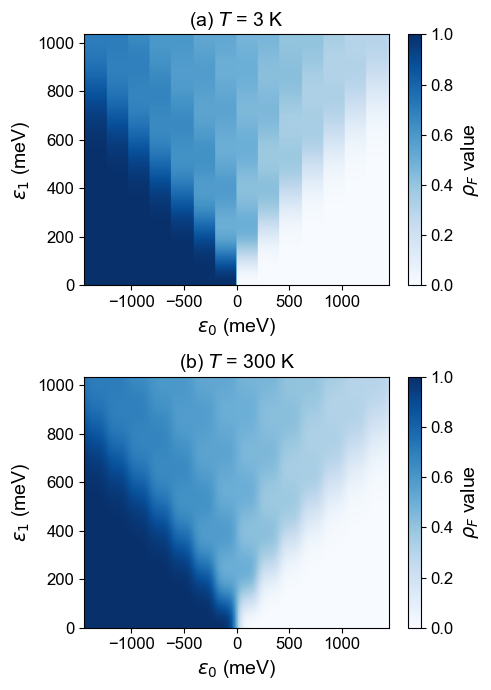

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(5, 7))

for idx, temp in enumerate(temp_arr):

    im = axes[idx].imshow(res[idx], cmap='Blues', vmin=0, vmax=1,
                         extent=[eps0_lo*1e3/ev_atomic,
                                 eps0_hi*1e3/ev_atomic,
                                 0,
                                 eps1_hi*1e3/ev_atomic],
                         origin='lower', aspect='auto')
    fig.colorbar(im, ax=axes[idx], label=rf'$\rho_F$ value')
    axes[idx].set_xlabel(r"$\epsilon_0$ (meV)")
    axes[idx].set_ylabel(r"$\epsilon_1$ (meV)")
    axes[idx].set_title(f'({chr(97+idx)}) $T$ = {temp:.0f} K')
    
    #axes[idx].text(0.05, 0.95, f"({chr(97+idx)})", transform=axes[idx].transAxes,
    #         fontsize=12, fontweight="bold", va="top", ha="left")


plt.tight_layout()
# plt.show()
plt.savefig("floquet_fermi.pdf", format="pdf")

In [10]:
print(rf'$\hbar\Omega$={1e3 * Omega/ev_atomic:.3g} meV')
print(rf'$k_B T$={1e3 * kb_atomic * temp /ev_atomic:.3g} meV')

$\hbar\Omega$=207 meV
$k_B T$=25.9 meV
